<a href="https://colab.research.google.com/github/vischia/adfm/blob/master/PA_02_neural_network_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Write your own DNN in python
## And classify houses with it

Copyright (c) Pietro Vischia, 2026

With some assistance from chatgpt 5.6 Sol ("High"), for the automated checks and assertions

You will analyze the "Housing" dataset, consisting in data on a set of houses in San Francisco and New York, with the goal of classifying houses based on their properties. The dataset is available via the https://github.com/jadeyee/r2d3-part-1-data , but I included a verbatim version in this notebook (in embedded form).

The goal is to classify houses as being New York or San Francisco houses, and contextually learn the inner workings of a neural network, including:
- The difference between stochastic gradient descent, batch gradient descent, and minibatch gradient descent
- How the *dropout* regularization technique works

### How to use this notebook
1. Read each **Predict $\to$ Code $\to$ Check $\to$ Discuss** prompt *before* inspecting its solution.
2. Fill the short `*_student` functions. All scaffolding and full reference implementations are supplied below them.
3. Add the exercise number to `SOLVED_EXERCISES` in the setup cell, then run **Restart kernel and Run All**. This activates your implementation and its checks. An empty set runs all supplied solutions, so this notebook runs out of the box.
4. Record your explanations in the answer cells. Expand the worked answers afterwards.

Let me stress that it is **crucial** that you try to fill the `*_student` functions by yourself before looking at the solutions, in order to maximise your learning. Do not replace missing code with calls to the reference solution.


This notebook has six exercise:
1. activation functions
2. forward propagation through a neural network
3. backwards pass through the neural network (*backpropagation*)
4. update of the weights
5. stochastic/batch/minibatch iterators
6. dropout


Either open in jupyter locally in the `adfm` environment, or in Google Colab.

Data are embedded, so no data download is needed. If imports fail on Google colab or conda, run `condainstall numpy pandas matplotlib scikit-learn` (in the conda environment) or `%pip install numpy pandas matplotlib scikit-learn` (on Google Colab) in a new cell (do not forget the `%` or `!` symbol before `pip`, to indicate jupyter that you want to run on the shell) and restart the kernel.

In [52]:
import io, gzip, base64, hashlib, time, sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

SOLVED_EXERCISES = set()  # e.g. {1, 2} after completing exercises 1 and 2
assert SOLVED_EXERCISES <= set(range(1, 7))
def choose(exercise, student, solution):
    return student if exercise in SOLVED_EXERCISES else solution

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True,
                     'grid.alpha': 0.2, 'font.size': 10})
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__,
      '| matplotlib:', matplotlib.__version__, '| scikit-learn:', sklearn.__version__)
print('Student implementations active:', sorted(SOLVED_EXERCISES))


Python: 3.10.21
NumPy: 2.2.5 | pandas: 2.3.3 | matplotlib: 3.10.9 | scikit-learn: 1.7.2
Student implementations active: []


## 1 · Data first: what may the network learn?

The original [R2D3 data](https://github.com/jadeyee/r2d3-part-1-data) are educational data, distributed under [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). The embedded, unmodified CSV (see below) preserves its attribution and licence notice. The authors request that it **not be used to draw conclusions about either real-estate market** (this is the typical USA disclaimer to fend off lawsuits by people who don't understand how to use simple tools).

**Discuss:** Why is scaling before splitting a form of information leakage? What information is allowed to influence the fitted weights, hyperparameters, and final reported performance?

In [53]:
# Original CSV snapshot retrieved 2026-10-13. Embedded for offline reproducibility.
# Source: https://raw.githubusercontent.com/jadeyee/r2d3-part-1-data/master/part_1_data.csv
DATA_GZIP_BASE64 = 'H4sIAAAAAAACA51bXW9kt5F996+4QF42wB0Nvz/8ZhheIEDWu4mzG+TJ6JF6rIbl1qS75cHk16dOkVVka6RuYS2PIHVd8pL1cepUkfrD8rf73XG525w2x+1p+bw5LrePDw/b29P2bvn4eFi+W/5vd3zaPCx/2p8Oj3dPt6fd4345PS7/tbm93+23y5+3m8N+t/9l+Y/70+nTt+/ff/78+ebg7vzN0/GPN8ufTgvNv/l9s3vYfHjYLk/7u+1h2SzfH7ab0+737fL942+/Pe6Py3en02H34QnTv/vxcY+Pt4fb3ebh3U/3m8P2u4fdr9sl3BgsZHvYb/AgLevPu9vt/rjVt9/2eW/btDePh1/eP7Rnju8/fHm3v3133Lyned7T4pa/b5f7x0/bZXda7rcPn47Ll8en5dNhQ7u83S53u48ft4ft/sT6WTb0vi9H7GZ/t/zOWtn9a9P0sb293+/++bQ93iz//eMPy19/+Mv//vDT375d/udhS4pd7h6X/eNpeaIfT6JvKPG3DW1qs/9CSt/fPjwdd9DE5sPj04me2y4/bj8v/3g8/LqQIX7a7Jf/PGz2t7vj7eNCu3xYtsfT5rSlSQ6/bk/0ZjXlMzt+3p3ul4dup5VXstvzzm63K/24/Lbb390s37774zd/+Ga3//n4cf2wvTuuHzan+/XTgVSxfqHRP3942j2c1uM/P57apz9/2h5+5l+3D9vfWRPfmNWtdq21GmNWWxN9w0/0Af3AUvrK0eBDZ0xabbCFHvR1FbH1TWwrnrHRrMmVtZLU0ldyfWrj14gfXGxCiIPvQm9YWHJpr70oxLSB10RC14Q1miGsIqSRWJQ1xV+Tuq4KW6rMbJsu8EmTe/pyRuVpdY5f7dYgc4sii1tzCTQshzW+RWhdEGleC81to3Wr77qw1ooJypoqKSJWw2PZQCZiUU1qfabt4NchNt1AZBeLJduU8lBItnGYKJLA0eK8DA619DdDC4lXSGpo6rqJq0tifku/sIlNGi/3YfIOW2CmkqK6h7cmtuktbZlMsbpiXFsbKQe7EeejB3wiv/TZ5uGcFnPq/PwTfdINQuIkSsc3Xp31fmjd1nl09e1bEi+TtYuXmcnLXhl7bWXq38l1cQorqZhcwq5FtEb2pYVj1zRRoNc756KKnTNjYWR9zJ+nV4fuxE2rkR7yNGTIU3RDTt8Kyf0bxtsr40VuU44DMbBy6+Fx7k3yOVLimgFF9Lphs6hWSV2vEaCjYl07DbaBlOXDmkWxVY1GKw8tFoY7kuvLYIrRQG/O0IC5OLeq7ZXJh1rr5DHOOBofUmGregyPpW2sFPqgOYw4FKAneQ2FHmkuBsORyuL4lTi5IY5V3ZFiyPN7bFAxa1xHA069j0mBzRaBJ/gBb80TQGqURzOBAP+Uo3lJzNvLQII4YZ8mmLxmvCD7xAaFMxRxBoqHwl5cE9uT47vO8OIlyLPMnEWcfPcVWRceyOqGdY2Bk1vl90LI6QdDsVIalM2QEapwiqyltKwGjWjKE1WR7fG2MvuA1dBNoYOxEVTht9o+OFieOfkpJb74WpW+uBv13cur6ublsYSQJKLEPQ2WFEHIzoMFDXpUjOSUCxzA9YzZcFL9MtAqSJKRcBXL0iSmLAgO4XOTMw1IQgNcw2AoRIRRhImEASYOLZ7w4qguG3jR2bux4yxeRTkRWakG/NKFJU/Chu6VYp2lFKkKT7RNzxTAa0b6/4rddTHnS5FSIBEHWks4y0g+aq6mrE6WKXkWh0nM6ORncMtJPLM2PlXinM6yG6NrTng+v0gS6VMPelPLG+T+0sbCS++mbQREObmBYH4RN6C4SBkks+YhfWVjuSPfYF7kRIwexXf/ZLFiF8Rp9sALOq+XdV4vK7V+hZsIKICQA312EvFRKAQpK+IRnssq75vENmBTwfohH7MXgAUhpPOVBEI6qwwn4h0L74wgd9hERyOsYNVE6nfxDXKO60nr2FmRRMvAXgf3B8blUEYMJMmiyXK2AKKpsV8VMpvMg01SOg6kcF9TagollBcv7W/GL8Q5ySKsM9a4FCXEkwN0Qv/NCNyl5MCg70Sd7FR4iD7BaoCDLrgp/BT5Y+k5wdupCgsgFMrJcoAp/EwuBnVhOS06xIk9hJLPOBvkQqTZz4OmUg/r0NyeqPb0gHET6/OwqNf8E+jL+mAmru4xjXF9CdCurWZ6INRMPljcpL+XtSt5pviouTwrO2Kv4P+z0iv6JfHSHCick9QaRpUbuKD0A39iKd10NBZBXib8afjCYUq/Uv5iuCLziu7tzJeRayiS8qvygLIK+BWv2DZesW28YluRx7mIcqQAyrq2DHn1c5FlItFCw2B4zfRRTW/jmemhIV/nB17xjXjNNwQvirL+0NgNl6rwHOKMwgOZJtL7HC0gJDMFn9UimOIyITYTqLuyDCXHKL6wM8IN5zszz9riAA8wFN0+ho6UjcCakWFScxTTxM18qhxsyBDvR4Wvcp90uGFNkXlKHlB7SW7nNACiYxpDYyHHVBg1h0dqYs8TtUQ/pCFyiVpHRMeRf3wjI1QP1YaGjKejteBRmOMV5LmNKjE9L1PWLx4kysShtxff7vJXjSVvO7c3cCyBekVbslnDA6t8heTaIqIwrwCyOMMpURAREzLD2cNMpV6e2z/n0sSRwQ8L2VUTW3aDKycGIXQ1pJrRJEBBnoEhpNG2ZU4RacpeMJaDn2TZktMYcMwsQEzJPZSlay3Uyig0dLzU1LpfcmHQ90BAV7Qer6PstSbSZAn71aTarVy4LYjuDiXNIjuyz4QlNg5OxQCZeqr8giVQRa6vl+ZVC7448TBgFI4AGGc0smEi+EH7K9AjbZD0KCUNZwM3koUH4QTxslcmV/LTDdUIKVXTcLeJcmZx7F5AVKv1w6src6KVLLUYeVUmz6xz9zK0EpCFidAGycDHCyO9JJFqwqjgI7mG4uM1KQUq66PzUOBAIG1FK1KBGCC+oZTLHaMqjic+7RoDBifK/pqQo8EPE1nKQVQUNM/ifOAEUym/gdtGPwmFlEOIjYDElUvTjkQRZGLC6ZwK18ZzCyhO4ooyJk5eZ5OWA2EFjSEaXK6O1ko6lwGXKGYsN0PF61wxcw0FWCFG3+TsG7Z1ONG6jsTpMw1OMtbmEf+U3SoQME0LV/JU8SlKrGon/3DOz+OhsYCHQk8VpUig04oo/6OwN25QGKv5W+fP2bUq7NL7tZOjxN7lNRUkuOoncVDeD31yRxHRXp91TFtvCtM7S0pkangTGR5DHZ0EyqF2Crpox+QZnmqN8OK5BRVTKxCtszPQmDyABmcOfmKOVpECfJOrLIPjBq0+RwLFlkD6fHflC+IXrMolnpGmkHpU1SIt97UXlIhhdP+r+qtNwN9oJmZi43SYQhoPIOXY5nlR0Zp3tLTeSlG9yuEQrS5xDRhWKTec5iSsulZQACKm9ro44AHtYFP0OwdszuRO5hvbXhxHbZrBmhIzJtvYfqhT4erR7QpNyubO83EX2gmxYjl95qwKIzQibK6gQ7UJydFGMxNMjOyVyBxeVjUdtUSwU4tzBxZiJVKh4PjHcOxyfMt7izbFM6LbtMbhW6TDShRbpKxIxshNjNAO3ozzP4+2r3U1juFp2nKmGGhJoivTo+qKGncZNLJJu0JE2Qh7S+/P7MQqt5ohKkdXXhmORWVpyngpE+Siz9tMxZ2dqISIk1qhfOyejeXzLLQAMzqyyfeFT/2L3A4gmv9akVfFagQUAyqhopF9JzOJU2QErl3s9SiAxYSt6OwQ6shoUnBRnRKq1+YLIibYHyqn2gux6x2L/RT1LTY8k1sqZ3RnyhPRWUxMew1a6k0tVVXaPJ9eTzEhrkKVpi3NnOi0udKtSe+FtcaboWgKSMQAa/zqA61LWOeNwVo4E/SxyTGBiROQY/H4J95W5o2DshcTNLyq6pTIa3atkTgppY55LbpGVJWvQQKolJHW4UjECwUvrJ+whsggToRCGmI3YyhivtSwjh2VeUNkLW52RdWYUzmAGbUnn/D28WudR6M5mGNkUGibMqNvQZUGp4fAlmY/cXlaeGQmVOfgm08UiFKtfICsQCgt21KR3umRDKVIfGgP3fIiGRWiP4cMDkw09vlQpoqdyug7FjSKLU4GrFhi6kpSVUAISjCdzHPs5sYRamEydBKQTLYoq8+ESiWjUOpDo+bx0mtZUh+twHcYtIPhkFuiR51dR8lmSKddlBaVoDjgcLKvHIwTio13wM7BPtcIXw6gyCO4i1aNPBIDTtgYSONwMFkYoMaTGVEfxiQoqDkaeQrntNh6km1bq5c/QlMZpWiKKol4zdFUmuXaio5Uv1o1M0CmtNmre01XJXDkyw6S84v69LQj9L5L1pQV1bH56I+iLvc19+q8dRVI2bU7dfNan0ukEranHPQkCHgrv9XdIAQkGaIREypUZZvX40YDH+NnfcCCZmY04wQKUh7nVZGJuMPLnqmTxUj+FGSz2GilbdpBGxrU3vQkr5vGURl6fa7iSLArtObpLgPaFeDB3oudQ8F/8G40rE07sfRFw7XIaLA4AqhCRCLG6+LQ1j0dkjgYiv6xH9C7gct5umjhAuEIlJZ1eje173AmQuNdiy3emZoEtIisiaAuYaQNbSMA/1KAppyCc28bs8Gx55yENk2VeIHrkR+gsugJi97SX8u1fcC1InQ2mycQMAu+mY4lBY1xGTuHDd9PoCwdSh+bp+2C2meychBT6MEkQhmdTocTFlg5wY7a7UPvJ0LNjvBeU1wex/iWS2aahbEAvFdP8Q2KA0rQodgm5T5mKIOtR4cbCVZwhPFeFhY6m4lE52Lqe9KeCNTPRIyW1nwTZKoUPWvyhPUBICKJKE1HsRYMEGHXkZfZaXNc7s+gvspAR5JGzunSinFtepxUlf5eWnSaTg5twptRZI0t14kCWjAvijlxS21Aomhims8XLmRhY2rWLK0LgF/eJNXWKYomS+AZsDuf1Kc1QeJUDQcdAQHv61seCPxAqr0rU7gs4QsoqPJkfeLd3FkNsbV0gsLzuL8EEKN8U2ISOLkobsiftRWZ0MgAu4mGbQY8mO7C4CAp9uMaTfLKQUFX5BZeDm+SZgkBkTp4k0iLeyZFdy+H50YD88AtHty+qrLnuRDie09IbEQ5W8qibUXNtbj1V7hJgGaEL5Kqy8iI3MEBtwqpR4nAf7tTCFKO/p3mWuU2vacMopjNNSGS6biFx21+chQYJUclgmU6xOb7DqA2YozBAZg3cxuPeGq16ouK7iG3fmikrOYljLKoDRU4bB1BodJzlRP0klfQojtN9EzYyjij5luLQEoBaI199JtwlyrySfdVaVq5E1FGmYM0m/iQUNKlnc7WXfJYU2lbTuzBVVGa6R56CrT+zB4e+wm10gAsvNXlHYipDhiA6ND3iUhdtk45TeITrBphwv3pJFWcelJgJopWAVfn4kpOXcm0Xlr2CBxeP33pPVbDhNIwlU5Zq1s9M4LbIxGhaVWUNGr4Qt45J2kc2zOtDa3uFkmtYOOsu4tCO2cRVJDIjsm8QejPeC70hEuq1fO6R0EypUbm9gFnn7KlXEavmc954e1R+ZEyHLTSQkQnoiuM7A1EC9PN4IBDQkShsl2nb0cv3/O5t+/yBtcuTrnI5ZC4nlKKVCfCS1vxfMGQpQ1RU5huF4bEXQfUZVU8LnV/bw5RwHVqT2bIo8lJPODaH7caM+3Sqcmtn2rviKqM1Kd8BzinwznSY0Q25bdbrcv5nhbfYomocgcN66mKSFbh6z1pgJdcq2yhyLUgKiD7AmTz4UMsvcnjRsPN8q0cvn1OEMPY07Q+LgXQ3DiACpTGkmT44sZtK86R3A2UNw+uxXO39lZpxMSv474E3C0kZmI1y7rE2LjvA8Ib0aax5rqYlod1j5soqPX4ViQp3Hdre9WZR4uZB1MWrMrlbHCTu7fWayijjClpVIUcZoa77VrMqrcBfgpXllkJ7tmlclxUsFzxlsYAQsPPMrV6Em67EnH3TfXjumsrt5kxumymvkfROgrLR+EJDau4uufi1LomfBgRx4V3h4NOT6lHaZtkHDQycVIQce9KTB7KuMiK8ipzC63rbAY2azLCMLT6PnA1IbdX+PSZgiOhfyUUOI1eN7fsoinS+GLu7Qa7tnz9GHe7teJNcoiA0XyMmqQwxN6nS7CgLcEHaZrZEQFsB9P6+JqdcxyRaS16v5TimST2NDg1tzy4DqAtytyaRvgwGiVpza0bw07az9K4lInox6F7UBVy03SezZdGCyeapFWlc5MlPdpbCZ3+kQT10pSLjQJz+5jZRUNNRUW+54XeN59s56SwFiZmk2id7Ypq1a7QdPs4OUYXW8b8TrWL3jagN2fTn5hQvR0OeST5hP6tdKTG38402wDagpcSYhIig+P+XJB2lM+T0ckwPYMH5bJmvizgcGDv6igjx9+5AFWBa+TQtRWDZ5k4WY6DgjoySao5O10xwXImS5qIx+XaxG0e/nuipHzQjG0xW8RBYhVEHhwc4sz3tGafidMFPxvZX/iam1dCeWZPsiCn4qS4NJ004ngC14H4L07KV0UAt8fRouH+oxteaSdyRLYsLWAJS6Rbouct3IdCtwO1obfPu5ToYUbcLw9T6ccN/y6Hbbxtl1rDaKPrFgBdNda1XYf1Sj6FWgKB+ECHi2M/3FYDi9zRg3iCYdr8dbYHOke+WIQsNwBYS5nKZ+RAXyBbyc+7Bdlx/y6BVpUqmGSnisFFy+TVhatSrja0A4wslwM3E/zULIrSrG9/jGC5LalRpcVK4Bs1FPAef1txVRrOqhUw9Z7ytRsalEAB7gkHcRHGDL+s2g/wfEMRpzrlq+YKv5fWC9+YT04iEUz8yYnhb3xoac8aClRyjJzo8GdOifv10xyuhmdPcMNteiJZe667YvjdAhsaHEBR8heAsW+55ryxX7ipDzbYU40749DqOTnjSFJSaJ0aULgpFKIduflMiqhKCXDd+WvRG5yxB1W2rdw7wzP0QTyfckmDkZj2REWcjbhRQ09ozzbNh3HJCZO6LmaepcdpKJ8Sevl6XDX+DoovC6M2N2gHjpnjuO/BIQysEwLlnB1TdzoT42ArF8+slLwin3E/EB3p0Cu41zqql4/HrzPHs8SFBsZLiev17BGbjxa9NobMh8Ow0n3IzTfAGfdh7jRIxTPSYQNKiXZvMF09Fr6Uz/8N8PtDO5o9AAA='
raw_csv = gzip.decompress(base64.b64decode(DATA_GZIP_BASE64))
assert hashlib.sha256(raw_csv).hexdigest() == '93ba9c6461bb45b31cba03a879eea865c8c96541869631b674d1f4bf15bd367c'
data_raw = pd.read_csv(io.BytesIO(raw_csv), comment='#')
data = data_raw.drop_duplicates().reset_index(drop=True)
assert set(data['in_sf'].unique()) == {0, 1}
assert np.isfinite(data.to_numpy(dtype=float)).all()
print(f'Rows: {len(data_raw)} original; {len(data)} after removing exact duplicates.')
display(data.head())
# you can give a numerical argument to `head`, indicating how many events you want to print from the beginning of the dataset
display(data.head(10))
# you can also print from the end, using `tail`
display(data.tail())


Rows: 492 original; 459 after removing exact duplicates.


,in_sf,beds,bath,price,year_built,sqft,price_per_sqft,elevation
0,0,2.0,1.0,999000,1960,1000,999,10
1,0,2.0,2.0,2750000,2006,1418,1939,0
2,0,2.0,2.0,1350000,1900,2150,628,9
3,0,1.0,1.0,629000,1903,500,1258,9
4,0,0.0,1.0,439000,1930,500,878,10


,in_sf,beds,bath,price,year_built,sqft,price_per_sqft,elevation
0,0,2.0,1.0,999000,1960,1000,999,10
1,0,2.0,2.0,2750000,2006,1418,1939,0
2,0,2.0,2.0,1350000,1900,2150,628,9
3,0,1.0,1.0,629000,1903,500,1258,9
4,0,0.0,1.0,439000,1930,500,878,10
5,0,1.0,1.0,475000,1920,500,950,10
6,0,1.0,1.0,975000,1930,900,1083,10
7,0,1.0,1.0,975000,1930,900,1083,12
8,0,2.0,1.0,1895000,1921,1000,1895,12
9,0,3.0,3.0,2095000,1926,2200,952,4


,in_sf,beds,bath,price,year_built,sqft,price_per_sqft,elevation
454,1,0.0,1.0,539000,2000,709,760,5
455,1,4.0,4.0,3760000,1894,3085,1219,49
456,1,5.0,2.5,1800000,1890,3073,586,76
457,1,2.0,1.0,695000,1923,1045,665,106
458,1,3.0,2.0,1650000,1922,1483,1113,106


We remove exact duplicate rows before splitting, to prevent identical records from appearing on both sides of a split. This does not establish that every remaining row represents an independent property; no property identifier is supplied. We use orthogonal **60% train / 20% validation / 20% test** partitions.

When preprocessing the data with a `scaler`, remember to always fit the `scaler` only on training features. **Never** scale the labels.

The labels (targets) are the variable `in_sf`: **1 = San Francisco (positive class), 0 = New York**. In particle-physics analogy, these play the roles of signal and background, but here the rows here are houses, not collision events.


In [54]:
feature_names = data.drop(columns='in_sf').columns.tolist()
X = data[feature_names].to_numpy(dtype=np.float64)
y = data['in_sf'].to_numpy(dtype=np.float64).reshape(-1, 1)
indices = np.arange(len(data))
idx_dev, idx_test = train_test_split(indices, test_size=0.20, stratify=y.ravel(), random_state=42)
idx_train, idx_val = train_test_split(idx_dev, test_size=0.25,
                                    stratify=y[idx_dev].ravel(), random_state=43)
assert not (set(idx_train) & set(idx_val) or set(idx_train) & set(idx_test)
            or set(idx_val) & set(idx_test))
scaler = MinMaxScaler().fit(X[idx_train])
X_train, X_val, X_test = [scaler.transform(X[i]) for i in (idx_train, idx_val, idx_test)]
y_train, y_val, y_test = [y[i] for i in (idx_train, idx_val, idx_test)]
N, D = X_train.shape
print('Features:', feature_names)
for name, labels in [('train', y_train), ('validation', y_val), ('test', y_test)]:
    print(f'{name:10s}: {len(labels):3d} rows, SF={int(labels.sum())}, NY={int((1-labels).sum())}')
print('Training majority-class accuracy:', max(y_train.mean(), 1-y_train.mean()))



Features: ['beds', 'bath', 'price', 'year_built', 'sqft', 'price_per_sqft', 'elevation']
train     : 275 rows, SF=148, NY=127
validation:  92 rows, SF=49, NY=43
test      :  92 rows, SF=50, NY=42
Training majority-class accuracy: 0.5381818181818182


## 2 · A network is a collection of matrices

We will use one hidden layer with **20 ReLU units**, followed by one sigmoid output (to output something that we can interpret as probability of belonging to a class). We will also learn the bias parameters (the order-zero terms in the perceptron equation).
This small network is enough to expose every calculation; deeper networks simply repeat the same operations, and you would not learn anything new.

For a batch of $m$ houses, with $d$ input features and $h=20$ hidden units:

| Quantity | Shape | Meaning |
|---|---|---|
| $X$ | $(m,d)$ | one row per house |
| $W_1$, $b_1$ | $(d,h)$, $(1,h)$ | hidden weights and biases |
| $Z_1=XW_1+b_1$ | $(m,h)$ | hidden preactivations |
| $A_1=\mathrm{ReLU}(Z_1)$ | $(m,h)$ | hidden activations |
| $W_2$, $b_2$ | $(h,1)$, $(1,1)$ | output weights and bias |
| $Z_2=A_1W_2+b_2$ | $(m,1)$ | output logits |
| $P=\sigma(Z_2)$ | $(m,1)$ | score estimating $P(\mathrm{SF}\mid X)$ |

Matrix multiplication `@` contracts the shared dimension. A bias broadcasts across rows. A sigmoid score lies in [0, 1], but it is not automatically a calibrated probability.

### Exercise 1: Activation functions
**Predict:** What are sigmoid(0), sigmoid′(0), ReLU(−2), and ReLU′(2)?

**Code:** Complete two lines. `sigmoid_student` uses `exp(-abs(z))` to avoid overflow. Its branching logic is supplied. Implement the derivative **with respect to the input logit**, using `s = sigmoid_student(z)`. In `relu_student`, keep positive values and zero the rest. We define the ReLU derivative at zero to be zero.


In [55]:
def sigmoid_student(z):
    z = np.asarray(z, dtype=float)
    t = np.exp(-np.abs(z))
    return np.where(z >= 0, 1/(1+t), t/(1+t))

def sigmoid_derivative_student(z):
    s = sigmoid_student(z)
    return None  # Derivative in terms of s

def relu_student(z):
    return None  # Elementwise maximum of z and zero


In [56]:
# Reference solution 1. Read only after trying the student cell.
def sigmoid(z):
    z = np.asarray(z, dtype=float)
    t = np.exp(-np.abs(z))
    return np.where(z >= 0, 1/(1+t), t/(1+t))

def sigmoid_derivative_solution(z):
    s = sigmoid(z)
    return s * (1-s)

def relu_solution(z):
    return np.maximum(0, z)


Now that you have coded your `*_student` functions, it's time to plot them!

Note that, in case you don't implement the student functions, the `choose` command below will run the reference solution (the only one with a return value).

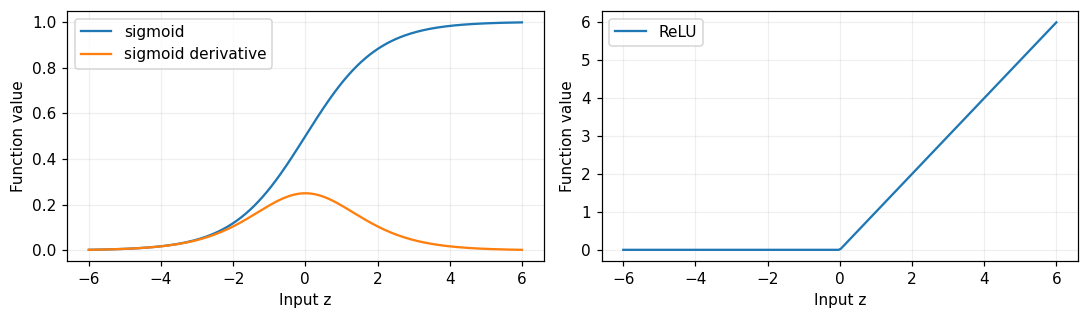

In [57]:

sigmoid_derivative = choose(1, sigmoid_derivative_student, sigmoid_derivative_solution)
relu = choose(1, relu_student, relu_solution)
np.testing.assert_allclose(sigmoid(np.array([-1000, 0, 1000])), [0, 0.5, 1])
np.testing.assert_allclose(sigmoid_derivative(np.array([0.])), [0.25])
np.testing.assert_array_equal(relu(np.array([-2., 0., 2.])), [0, 0, 2])
z = np.linspace(-6, 6, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(z, sigmoid(z), label='sigmoid')
axes[0].plot(z, sigmoid_derivative(z), label='sigmoid derivative')
axes[1].plot(z, relu(z), label='ReLU')
for ax in axes:
    ax.set(xlabel='Input z', ylabel='Function value'); ax.legend()
plt.tight_layout(); plt.show()


### Initialize the parameters

Now we have to initialize the network weights. For the hidden weights, we will use a standard deviation of $\sqrt{2/d}$, , appropriate to ReLU (He initialization); the output weights use √(1/h). Biases start at zero. Random, asymmetric weights allow hidden units to learn different features. Never initialize every weight to zero.

**Check:** How many trainable parameters are there? Calculate it! Don't forget to include in the calculation both bias vectors (hint: bias vectors increase by one the size of the input vector to each layer).


In [58]:
def initialize(n_inputs, n_hidden=20, seed=0):
    rng = np.random.default_rng(seed)
    return {'W1': rng.normal(0, np.sqrt(2/n_inputs), (n_inputs, n_hidden)),
            'b1': np.zeros((1, n_hidden)),
            'W2': rng.normal(0, np.sqrt(1/n_hidden), (n_hidden, 1)),
            'b2': np.zeros((1, 1))}

def copy_params(params):
    return {key: value.copy() for key, value in params.items()}

initial_params = initialize(D, seed=7)
print({key: value.shape for key, value in initial_params.items()})
print('Parameters:', sum(value.size for value in initial_params.values()))


{'W1': (7, 20), 'b1': (1, 20), 'W2': (20, 1), 'b2': (1, 1)}
Parameters: 181


<details>
<summary>Worked answer — open after discussing</summary>

There are d×h + h + h×1 + 1 parameters. With seven features and 20 hidden units, this is 181. Biases shift activation thresholds without requiring a constant feature column.

</details>

### Exercise 2: the forward pass (propagate the inputs to the predictions)

**Code:** First propagate `Xb` to `Z1`, apply `relu`, then propagate `A1` to `Z2` and apply `sigmoid`. Preserve the 2D shapes, even for a single house. Return a cache (i.e. don't erase the intermediate arrays, return them together with the rest of the forward output): backpropagation will need these intermediate arrays.

**Predict:** Why must `W1` have shape `(D, 20)` rather than `(20, D)` under our row-per-house convention?


In [59]:
def forward_core_student(Xb, params):
    Z1 = None  # Matrix multiply, then add hidden bias
    A1 = None  # Hidden activation
    Z2 = None  # Propagate to output logit, including bias
    P = None   # Output probability
    return P, {'X': Xb, 'Z1': Z1, 'A1': A1, 'A1_used': A1,
               'Z2': Z2, 'mask': np.ones_like(A1)}


In [60]:
# Reference solution 2. Read only after trying the student cell.

def forward_core_solution(Xb, params):
    Z1 = Xb @ params['W1'] + params['b1']
    A1 = relu(Z1)
    Z2 = A1 @ params['W2'] + params['b2']
    P = sigmoid(Z2)
    return P, {'X': Xb, 'Z1': Z1, 'A1': A1, 'A1_used': A1,
               'Z2': Z2, 'mask': np.ones_like(A1)}

forward_core = choose(2, forward_core_student, forward_core_solution)
P0, cache0 = forward_core(X_train[:5], initial_params)
assert P0.shape == (5, 1) and cache0['Z1'].shape == (5, 20)
assert np.isfinite(P0).all() and ((P0 >= 0) & (P0 <= 1)).all()
# Independent hand-calculable example, including nonzero biases.
toy = {'W1': np.array([[1., -1.], [2., 1.]]), 'b1': np.array([[0.5, 0.]]),
       'W2': np.array([[2.], [-1.]]), 'b2': np.array([[0.25]])}
ptoy, ctoy = forward_core(np.array([[1., 2.]]), toy)
np.testing.assert_allclose(ctoy['Z1'], [[5.5, 1.]])
np.testing.assert_allclose(ctoy['Z2'], [[10.25]])
np.testing.assert_allclose(ptoy, sigmoid([[10.25]]))
print('Untrained probabilities:', P0.ravel().round(3))


Untrained probabilities: [0.456 0.475 0.49  0.463 0.49 ]


### Setup the loss function

Use the **mean binary cross-entropy** (BCE) over the current batch:

$$L=-\frac1m\sum_i [y_i\log p_i+(1-y_i)\log(1-p_i)].$$

REMINDER: a logit is the prediction as it comes out from the linear layer that precedes the last activation function.

Compute the BCE from the logits for numerical stability:

$$L=\frac1m\sum_i[\log(1+e^{z_i})-y_i z_i].$$

`np.logaddexp(0, z)` computes the first term stably, even for very large logits. Avoid ad hoc replacements for `log(0)` and avoid confusing Python's XOR operator `^` with exponentiation `**`.

For sigmoid output plus BCE, the chain rule simplifies to:

$$\frac{\partial L}{\partial Z_2}=\frac{P-y}{m}.$$

**Do not multiply by the sigmoid derivative again**: it has already cancelled in this expression. This differs from the gradient for squared error with sigmoid output.


In [61]:
def bce_from_logits(logits, targets):
    assert logits.shape == targets.shape
    return float(np.mean(np.logaddexp(0.0, logits) - targets * logits))

np.testing.assert_allclose(bce_from_logits(np.zeros((2, 1)), np.array([[0.], [1.]])), np.log(2))
assert np.isfinite(bce_from_logits(np.array([[-1000.], [1000.]]), np.array([[1.], [0.]])))
print('Untrained BCE:', bce_from_logits(cache0['Z2'], y_train[:5]))


Untrained BCE: 0.7451381977856386


### Exercise 3: propagate the gradient backwards (the backpropagation core)

The output-layer derivatives are supplied. **Now propagate `dZ2` back through `W2` to the hidden activations, then through ReLU to `Z1`, and finally to `W1` and `b1`.** Do not change any of the parameters (network weights) while propagating gradients. The equations you will need are:

$$\begin{aligned}
G_{W_2}&=\widetilde A_1^T dZ_2,&G_{b_2}&=\sum_{rows}dZ_2,\\
dA_1&=(dZ_2 W_2^T)\odot M,&dZ_1&=dA_1\odot\mathbf1[Z_1>0],\\
G_{W_1}&=X^T dZ_1,&G_{b_1}&=\sum_{rows}dZ_1.
\end{aligned}$$

At present $M=1$ and $\widetilde A_1=A_1$. In exercise 6, $M$ will be the **scaled dropout mask**, and $\widetilde A_1=A_1\odot M$. Including it here will make the backward pass ready for dropout.

**Code:** Complete four lines, keeping the bias derivatives 2D with `keepdims=True`. Division by `m` occurs once, in `dZ2`.


In [62]:
def backward_student(P, yb, cache, params):
    m = len(yb)
    dZ2 = (P - yb) / m
    dW2 = cache['A1_used'].T @ dZ2
    db2 = dZ2.sum(axis=0, keepdims=True)
    dA1 = None  # Propagate through W2, then multiply by cached mask
    dZ1 = None  # Propagate through ReLU; inspect preactivations
    dW1 = None  # Propagate to hidden weights
    db1 = None  # Aggregate hidden bias derivatives over rows
    return {'W1': dW1, 'b1': db1, 'W2': dW2, 'b2': db2}

In [63]:
# Reference solution 3. Read only after trying the student cell.

def backward_solution(P, yb, cache, params):
    dZ2 = (P - yb) / len(yb)
    dW2 = cache['A1_used'].T @ dZ2
    db2 = dZ2.sum(axis=0, keepdims=True)
    dA1 = (dZ2 @ params['W2'].T) * cache['mask']
    dZ1 = dA1 * (cache['Z1'] > 0)
    dW1 = cache['X'].T @ dZ1
    db1 = dZ1.sum(axis=0, keepdims=True)
    return {'W1': dW1, 'b1': db1, 'W2': dW2, 'b2': db2}

backward = choose(3, backward_student, backward_solution)
grads0 = backward(P0, y_train[:5], cache0, initial_params)
for key in initial_params:
    assert grads0[key].shape == initial_params[key].shape
    assert np.isfinite(grads0[key]).all()
print('Gradient shapes:', {k: v.shape for k, v in grads0.items()})


Gradient shapes: {'W1': (7, 20), 'b1': (1, 20), 'W2': (20, 1), 'b2': (1, 1)}


### Exercise 4: Update all the network parameters (weights)

Only after having completed the backward pass, apply the equation for the update of the weights, $\theta \leftarrow \theta - \eta\nabla L$, to every weight and bias. Here gradients mean derivatives of the loss, so the update uses a minus sign. Return a new dictionary; leave the old parameters unchanged.


In [64]:
def step_student(params, grads, learning_rate):
    return {key: None for key in params}  # Replace None with the descent update


In [65]:
# Reference solution 4. Read only after trying the student cell.

def step_solution(params, grads, learning_rate):
    return {key: params[key] - learning_rate * grads[key] for key in params}

step = choose(4, step_student, step_solution)
saved = copy_params(initial_params)
updated = step(initial_params, grads0, 1e-3)
for key in initial_params:
    np.testing.assert_array_equal(initial_params[key], saved[key])
    np.testing.assert_allclose(updated[key], saved[key] - 1e-3 * grads0[key])
_, c_updated = forward_core(X_train[:5], updated)
assert bce_from_logits(c_updated['Z2'], y_train[:5]) < bce_from_logits(cache0['Z2'], y_train[:5])
print('A sufficiently small gradient step lowered the loss on the same batch.')


A sufficiently small gradient step lowered the loss on the same batch.


### Check the calculus numerically

For a parameter $\theta_j$, compare backpropagation with the central difference
$[L(\theta_j+\epsilon)-L(\theta_j-\epsilon)]/(2\epsilon)$.
We check every parameter of a small network, using a toy input away from ReLU's kink at zero. This catches incorrect transposes, signs, bias sums, and factors of batch size.

When coding, it is always important to check everything works properly with very simple inputs

In [66]:
def gradient_check(forward_fn, dropout_rate=0.0):
    params = initialize(3, n_hidden=4, seed=81)
    xb = np.random.default_rng(82).normal(size=(5, 3))
    yb = np.array([[0.], [1.], [0.], [1.], [1.]])
    def evaluate(p):
        # Recreate this RNG on every call: finite differences need the SAME mask.
        return forward_fn(xb, p, training=True, dropout_rate=dropout_rate,
                          rng=np.random.default_rng(83))
    prob, cache = evaluate(params)
    assert np.min(np.abs(cache['Z1'])) > 1e-4
    analytic = backward(prob, yb, cache, params)
    numeric = {k: np.zeros_like(v) for k, v in params.items()}
    eps = 1e-6
    for key, value in params.items():
        for index in np.ndindex(value.shape):
            plus, minus = copy_params(params), copy_params(params)
            plus[key][index] += eps
            minus[key][index] -= eps
            _, cp = evaluate(plus)
            _, cm = evaluate(minus)
            numeric[key][index] = (bce_from_logits(cp['Z2'], yb)
                                   - bce_from_logits(cm['Z2'], yb)) / (2*eps)
        np.testing.assert_allclose(analytic[key], numeric[key], rtol=2e-5, atol=2e-7)
    err = max(np.max(np.abs(analytic[k] - numeric[k])) for k in params)
    print(f'Gradient check passed (dropout={dropout_rate:g}); max absolute error = {err:.2e}')

def no_dropout_forward(Xb, params, **kwargs):
    return forward_core(Xb, params)
gradient_check(no_dropout_forward)


Gradient check passed (dropout=0); max absolute error = 1.00e-10


## One optimizer, three different batch sizes and gradient update schemes

Since we are at it, we will try to implement dropout (the regularizer) while we implement the gradient update schemes)

| `Scheme` | Rows used for each update | Updates per epoch |
|---|---|---|
| `stochastic` | 1 | $N$ |
| `batch` | all $N$ training rows | 1 |
| `minibatch` | up to `batch_size` | $\lceil N/\text{batch\_size}\rceil$ |

An **epoch** is one pass through all training rows. For stochastic and minibatch descent we use a new random permutation each epoch (random reshuffling, without replacement within that epoch). Keep the final, possibly smaller batch and divide its loss gradient by its **actual** size. A full batch averages all training examples before updating any parameter.

### Exercise 5: stochastic/batch/minibatch iterators

**Predict:** For N=10 and minibatch size 4, what are the batch sizes? How many updates?

**Code:** Set `size` for the three schemes, then yield slices of the permutation. The checks verify full coverage, no repeats, and the short final batch.

In [67]:
# Note: `size` is to be filled from your knowledge and from the input arguments of the function.
# You have all the information needed
def batch_indices_student(n, scheme, batch_size, rng):
    if scheme == 'stochastic':
        size = None  # this is a fixed number
    elif scheme == 'batch':
        size = None  # this is a fixed number
    elif scheme == 'minibatch':
        size = None  # this is a number that you can choose, with some boundaries. Which boundaries?
    else:
        raise ValueError('Unknown scheme')
    order = np.arange(n) if scheme == 'batch' else rng.permutation(n)
    for start in range(0, n, size):
        yield None  # Slice order, including any short final batch

In [68]:
# Reference solution 5. Read only after trying the student cell.

def batch_indices_solution(n, scheme, batch_size, rng):
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError('n must be a positive integer')
    if scheme == 'stochastic':
        size = 1
    elif scheme == 'batch':
        size = n
    elif scheme == 'minibatch':
        if not isinstance(batch_size, (int, np.integer)) or batch_size < 1:
            raise ValueError('batch_size must be a positive integer')
        size = int(batch_size)
    else:
        raise ValueError('scheme must be stochastic, batch or minibatch')
    order = np.arange(n) if scheme == 'batch' else rng.permutation(n)
    for start in range(0, n, size):
        yield order[start:start+size]

batch_indices = choose(5, batch_indices_student, batch_indices_solution)
for scheme, sizes in [('stochastic', [1]*10), ('batch', [10]), ('minibatch', [4, 4, 2])]:
    batches = list(batch_indices(10, scheme, 4, np.random.default_rng(2)))
    assert [len(b) for b in batches] == sizes
    np.testing.assert_array_equal(np.sort(np.concatenate(batches)), np.arange(10))
    print(scheme, 'batch sizes:', [len(b) for b in batches])
assert len(list(batch_indices(10, 'minibatch', 20, np.random.default_rng(2)))) == 1


stochastic batch sizes: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
batch batch sizes: [10]
minibatch batch sizes: [4, 4, 2]


<details>
<summary>Worked answer — open after discussing</summary>

The minibatch sizes are 4, 4 and 2; there are three updates. Stochastic descent makes ten updates, while batch descent makes one. A minibatch size at least N gives one full-data update. A minibatch size of one gives stochastic descent when order, initialization and learning rate match.

</details>


## Dropout: switch units off only while training, with the effect of a regularization technique

### Exercise 6: Inverted dropout

Let $r$ be the **drop probability** and $q=1-r$ the keep probability. For each row and hidden unit independently, draw $K_{ij}\sim\mathrm{Bernoulli}(q)$ and use

$$M=K/q,\qquad \widetilde A_1=A_1\odot M.$$

Then $\mathbb E[\widetilde A_1\mid A_1]=A_1$. The factor $1/q$ is applied **during training**, so evaluation uses the unmodified activations and needs no rescaling. Dropout is applied after hidden ReLU, never to the output probability. Draw a fresh mask for each training forward pass; cache and reuse that very mask in the backward pass.

**Code:** Draw a mask using `rng.random(A.shape)`, compare it with `q`, then scale it. This is equivalent to sampling from a Bernoulli distribution with `p = rate` and `q = -(rate)` Return both the dropped activation and the scaled mask. The no-dropout/evaluation branch is supplied.

**Discuss:** Why must backpropagation multiply by the same scaled mask? Why should validation use `training=False`?


In [69]:
def dropout_student(A, rate, training, rng):
    if not 0 <= rate < 1:
        raise ValueError('dropout rate must be in [0, 1)')
    if not training or rate == 0:
        return A, np.ones_like(A)
    q = 1-rate
    mask = None  # Bernoulli keep mask divided by q
    return None, mask  # Multiply A elementwise by this mask

In [70]:
# Reference solution 6. Read only after trying the student cell.

def dropout_solution(A, rate, training, rng):
    if not 0 <= rate < 1:
        raise ValueError('dropout rate must be in [0, 1)')
    if not training or rate == 0:
        return A, np.ones_like(A)
    if rng is None:
        raise ValueError('Provide an RNG for training with dropout')
    q = 1-rate
    mask = (rng.random(A.shape) < q).astype(float) / q
    return A * mask, mask



In [71]:
dropout = choose(6, dropout_student, dropout_solution)

def forward(Xb, params, training=False, dropout_rate=0.0, rng=None):
    # Reuse the forward core you wrote. Recompute the output after dropout.
    P, cache = forward_core(Xb, params)
    A1_used, mask = dropout(cache['A1'], dropout_rate, training, rng)
    Z2 = A1_used @ params['W2'] + params['b2']
    cache.update(A1_used=A1_used, mask=mask, Z2=Z2)
    return sigmoid(Z2), cache

ones = np.ones((10000, 20))
dropped, mask = dropout(ones, 0.25, True, np.random.default_rng(9))
assert abs(dropped.mean() - 1) < 0.01
assert abs(np.mean(mask == 0) - 0.25) < 0.01
np.testing.assert_allclose(np.unique(mask), [0, 1/0.75])
np.testing.assert_array_equal(dropout(ones, 0.25, False, None)[0], ones)
np.testing.assert_array_equal(dropout(ones, 0, True, None)[0], ones)
peval1, _ = forward(X_train[:5], initial_params, dropout_rate=0.25)
peval2, _ = forward(X_train[:5], initial_params, dropout_rate=0.25)
np.testing.assert_array_equal(peval1, peval2)
np.testing.assert_allclose(peval1, P0)
gradient_check(forward, dropout_rate=0.25)
print('Dropout checks passed; evaluation predictions are deterministic.')


Gradient check passed (dropout=0.25); max absolute error = 5.69e-11
Dropout checks passed; evaluation predictions are deterministic.


<details>
<summary>Worked answer — open after discussing</summary>

The local derivative of A×M with respect to A is M. Dropped units receive zero gradient through that activation; kept units receive the same 1/q factor used in the forward pass. Drawing a different mask in the backward pass would differentiate a different function. Deterministic validation measures the inference network rather than a randomly thinned network. Preserving expected hidden activations does not imply that the full nonlinear network exactly equals the average of all dropout networks.

</details>

## Put it all together: a full training loop

For each epoch: construct batches $\to$ forward pass with dropout active $\to$ compute gradients $\to$ update **all** parameters $\to$ measure train and validation metrics with dropout **disabled**.

All logged losses are evaluated on the complete corresponding split using one fixed parameter state, after the epoch. They are not averages of online losses from changing models. This makes train and validation curves comparable, including when training used dropout.

The loop records epoch, cumulative updates, examples seen and elapsed time. It returns the final parameters and the checkpoint with the smallest validation BCE (including the initial model at epoch 0). It never receives the test set. For paired comparisons, initialization, shuffle and dropout each have their own random stream; changing dropout cannot change the data order.


In [72]:
def metrics(params, Xb, yb):
    P, cache = forward(Xb, params, training=False)
    return {'loss': bce_from_logits(cache['Z2'], yb),
            'accuracy': float(np.mean((P >= 0.5) == yb))}

def train(Xtr, ytr, Xva, yva, *, scheme='minibatch', batch_size=32,
          dropout_rate=0.0, learning_rate=0.05, epochs=120,
          seed=0, n_hidden=20):
    if scheme not in ('stochastic', 'batch', 'minibatch'):
        raise ValueError('Unknown scheme')
    if not 0 <= dropout_rate < 1 or learning_rate <= 0:
        raise ValueError('Invalid dropout rate or learning rate')
    if not isinstance(epochs, (int, np.integer)) or epochs < 1:
        raise ValueError('epochs must be a positive integer')
    assert Xtr.ndim == Xva.ndim == 2 and Xtr.shape[1] == Xva.shape[1]
    assert ytr.shape == (len(Xtr), 1) and yva.shape == (len(Xva), 1)
    params = initialize(Xtr.shape[1], n_hidden, seed=seed)
    shuffle_rng = np.random.default_rng(seed + 10000)
    dropout_rng = np.random.default_rng(seed + 20000)
    updates, seen = 0, 0
    rows = []
    start_time = time.perf_counter()
    best_loss, best_epoch, best_params = np.inf, 0, copy_params(params)
    for epoch in range(epochs + 1):
        if epoch > 0:
            for ids in batch_indices(len(Xtr), scheme, batch_size, shuffle_rng):
                P, cache = forward(Xtr[ids], params, training=True,
                                   dropout_rate=dropout_rate, rng=dropout_rng)
                grads = backward(P, ytr[ids], cache, params)
                params = step(params, grads, learning_rate)
                updates += 1
                seen += len(ids)
        tr, va = metrics(params, Xtr, ytr), metrics(params, Xva, yva)
        if not np.isfinite([tr['loss'], va['loss']]).all():
            raise FloatingPointError('Nonfinite loss: inspect gradients or lower learning_rate')
        rows.append({'epoch': epoch, 'updates': updates, 'examples_seen': seen,
                     'seconds': time.perf_counter()-start_time,
                     'train_loss': tr['loss'], 'val_loss': va['loss'],
                     'train_accuracy': tr['accuracy'], 'val_accuracy': va['accuracy']})
        if va['loss'] < best_loss:
            best_loss, best_epoch, best_params = va['loss'], epoch, copy_params(params)
    return {'final_params': params, 'best_params': best_params,
            'best_epoch': best_epoch, 'history': pd.DataFrame(rows)}

# Equivalence checks on real training rows, with the same order and RNG streams.
small = (X_train[:10], y_train[:10], X_val[:8], y_val[:8])
a = train(*small, scheme='stochastic', epochs=2, seed=11, dropout_rate=0.25)
b = train(*small, scheme='minibatch', batch_size=1, epochs=2, seed=11, dropout_rate=0.25)
for key in a['final_params']:
    np.testing.assert_allclose(a['final_params'][key], b['final_params'][key])
a = train(*small, scheme='batch', epochs=2, seed=11)
b = train(*small, scheme='minibatch', batch_size=10, epochs=2, seed=11)
for key in a['final_params']:
    np.testing.assert_allclose(a['final_params'][key], b['final_params'][key], atol=1e-12)
for scheme, count in [('stochastic', 10), ('batch', 1), ('minibatch', 3)]:
    run = train(*small, scheme=scheme, batch_size=4, epochs=2)
    assert run['history']['updates'].iloc[-1] == 2*count
    assert run['history']['examples_seen'].iloc[-1] == 20
print('Training-loop checks passed, including the short final minibatch.')


Training-loop checks passed, including the short final minibatch.


## Comparison between the 3 schemes with 2 different dropout settings each

**Before running, predict:** Which curve will improve fastest per epoch? Which run will take longest? Will dropout necessarily help on this small dataset?

For the main comparison hold fixed the split, preprocessing, architecture (20 hidden units), learning rate (0.05), and epoch count (120). Compare `stochastic`, `batch`, and `minibatch` (size 32), each with drop probability **0 or 0.25**. Run three paired seeds, with identical initial weights within each seed. The train/validation split stays fixed, so the spread reflects training randomness, **not uncertainty over possible datasets**.

Equal epochs mean equal examples processed, but unequal updates and elapsed time. A common learning rate is a controlled teaching baseline, not an individually optimized contest. Do not conclude that a method is intrinsically better from this one setting. Per-scheme learning-rate tuning is an extension below.

The learning curves use every epoch; final-epoch bars compare the same epoch budget. Best-validation checkpoints are used only for the final selected-model diagnostic. Runtime includes epoch-end metrics and Python overhead; it is not a hardware-independent benchmark.


In [73]:
SCHEMES = ['stochastic', 'batch', 'minibatch']
DROP_RATES = [0.0, 0.25]
SEEDS = [7, 19, 41]  # use one seed for a quicker first pass; restore all three for discussion
EPOCHS = 120
LEARNING_RATE = 0.05
BATCH_SIZE = 32
COLORS = dict(zip(SCHEMES, ['#167d9a', '#d47a25', '#7454ad']))

def label(scheme, rate):
    return f'{scheme}, dropout={rate:g}'

runs = {}
for seed in SEEDS:
    for scheme in SCHEMES:
        for rate in DROP_RATES:
            runs[(scheme, rate, seed)] = train(
                X_train, y_train, X_val, y_val, scheme=scheme,
                batch_size=BATCH_SIZE, dropout_rate=rate,
                learning_rate=LEARNING_RATE, epochs=EPOCHS, seed=seed)
    print(f'Completed seed {seed}')

records = []
for (scheme, rate, seed), run in runs.items():
    end = run['history'].iloc[-1]
    records.append({'scheme': scheme, 'dropout': rate, 'seed': seed,
                    'final_train_BCE': end.train_loss, 'final_val_BCE': end.val_loss,
                    'final_val_accuracy': end.val_accuracy,
                    'gap_BCE': end.val_loss-end.train_loss,
                    'best_val_BCE': run['history'].val_loss.min(),
                    'best_epoch': run['best_epoch'], 'updates': int(end.updates),
                    'seconds': end.seconds})
results = pd.DataFrame(records)
display(results.groupby(['scheme', 'dropout'], sort=False).agg(
    final_val_BCE=('final_val_BCE', 'mean'),
    final_val_accuracy=('final_val_accuracy', 'mean'),
    gap_BCE=('gap_BCE', 'mean'), updates=('updates', 'first'),
    mean_seconds=('seconds', 'mean')).round(4))


Completed seed 7
Completed seed 19
Completed seed 41


final_val_BCE  final_val_accuracy  gap_BCE  updates  \
scheme     dropout                                                        
stochastic 0.00            0.2492              0.9058   0.0174    33000   
           0.25            0.2523              0.9167   0.0174    33000   
batch      0.00            0.6088              0.7609   0.0017      120   
           0.25            0.6126              0.7645   0.0019      120   
minibatch  0.00            0.3106              0.9058  -0.0042     1080   
           0.25            0.3335              0.8986  -0.0027     1080   

                    mean_seconds  
scheme     dropout                
stochastic 0.00           0.8312  
           0.25           0.8705  
batch      0.00           0.0178  
           0.25           0.0207  
minibatch  0.00           0.0437  
           0.25           0.0493

### First output: Learning curves at an equal epoch budget

Solid curves are training BCE; dashed curves are validation BCE. Shading shows ±1 sample standard deviation across seeds (no shading if only one seed). All metrics use dropout-free inference. Look for stalled optimization, decreasing training loss, and any train–validation divergence.


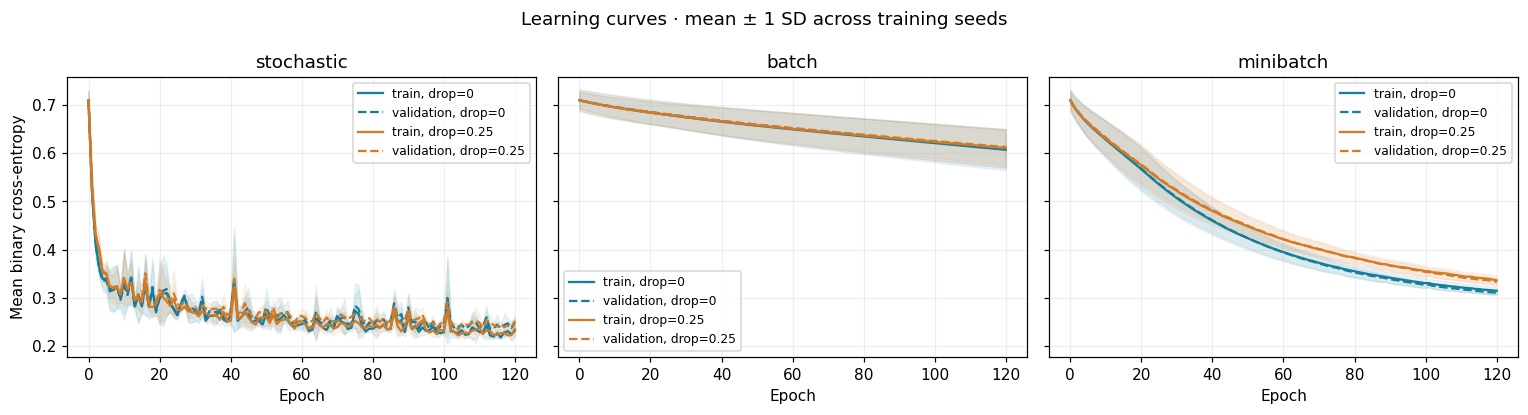

In [74]:
def mean_sd(values):
    values = np.asarray(values)
    return values.mean(axis=0), (values.std(axis=0, ddof=1) if len(values)>1
                                  else np.zeros_like(values[0]))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True, sharey=True)
for ax, scheme in zip(axes, SCHEMES):
    for rate, color in zip(DROP_RATES, ['#167d9a', '#d47a25']):
        for metric, style, split in [('train_loss', '-', 'train'), ('val_loss', '--', 'validation')]:
            hs = [runs[(scheme, rate, s)]['history'] for s in SEEDS]
            avg, sd = mean_sd([h[metric].to_numpy() for h in hs])
            epochs = hs[0]['epoch'].to_numpy()
            ax.plot(epochs, avg, style, color=color, label=f'{split}, drop={rate:g}')
            ax.fill_between(epochs, avg-sd, avg+sd, color=color, alpha=0.08)
    ax.set(title=scheme, xlabel='Epoch'); ax.legend(fontsize=8)
axes[0].set_ylabel('Mean binary cross-entropy')
fig.suptitle('Learning curves · mean ± 1 SD across training seeds')
plt.tight_layout(); plt.show()


### Second output: the horizontal axis changes the question

Compare mean validation BCE against **epochs**, **cumulative parameter updates**, and **elapsed seconds**. The last two axes use a symmetric logarithmic scale to include zero and show the different budgets. Each point is an epoch-end measurement; no within-epoch loss was measured. The time coordinate is the mean elapsed time across seeds at that epoch.

The update plot re-expresses the same runs; it is not a separately trained equal-update-budget experiment. One full-batch update touches N examples, whereas one stochastic update touches one. Neither epochs nor updates alone measure all computational costs.


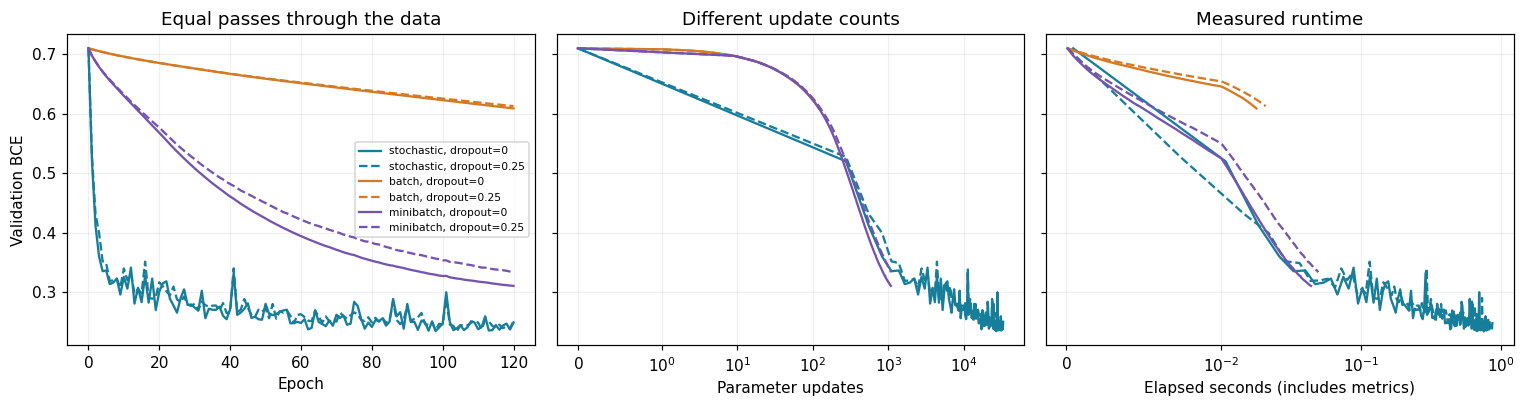

In [75]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for scheme in SCHEMES:
    for rate in DROP_RATES:
        hs = [runs[(scheme, rate, s)]['history'] for s in SEEDS]
        avg, _ = mean_sd([h.val_loss.to_numpy() for h in hs])
        for ax, xkey in zip(axes, ['epoch', 'updates', 'seconds']):
            xavg = np.mean([h[xkey].to_numpy() for h in hs], axis=0)
            ax.plot(xavg, avg, color=COLORS[scheme], linestyle='-' if rate == 0 else '--',
                    label=label(scheme, rate))
axes[0].set(xlabel='Epoch', ylabel='Validation BCE', title='Equal passes through the data')
axes[1].set(xlabel='Parameter updates', title='Different update counts')
axes[1].set_xscale('symlog', linthresh=1)
axes[2].set(xlabel='Elapsed seconds (includes metrics)', title='Measured runtime')
axes[2].set_xscale('symlog', linthresh=0.01)
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Third output: does dropout improve generalization here?

Compare final validation BCE (lower is better), validation accuracy at threshold 0.5 (higher is better), and the BCE gap **validation minus training**. Error bars show one sample SD across seeds. A smaller gap alone does not prove improvement: it can also arise when both losses are poor.


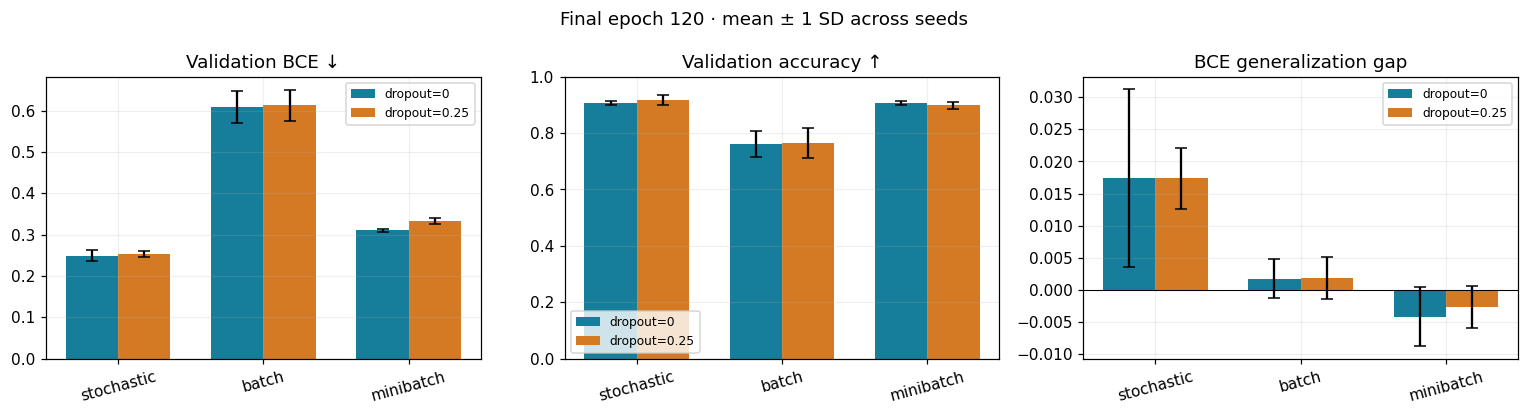

Paired change in final validation BCE (negative favours dropout):


dropout          dropout_minus_no_dropout
scheme     seed                          
batch      7                       0.0028
           19                      0.0066
           41                      0.0019
minibatch  7                       0.0262
           19                      0.0199
           41                      0.0224
stochastic 7                       0.0178
           19                     -0.0083
           41                     -0.0001

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
xpos = np.arange(len(SCHEMES))
for j, rate in enumerate(DROP_RATES):
    for ax, metric, title in zip(axes,
        ['final_val_BCE', 'final_val_accuracy', 'gap_BCE'],
        ['Validation BCE ↓', 'Validation accuracy ↑', 'BCE generalization gap']):
        values = [results[(results.scheme==s) & (results.dropout==rate)][metric].to_numpy()
                  for s in SCHEMES]
        means = [v.mean() for v in values]
        sds = [v.std(ddof=1) if len(v)>1 else 0 for v in values]
        ax.bar(xpos+(j-0.5)*0.36, means, width=0.36, yerr=sds, capsize=4,
               color=['#167d9a', '#d47a25'][j], label=f'dropout={rate:g}')
        ax.set_xticks(xpos, SCHEMES, rotation=15)
        ax.set_title(title); ax.legend(fontsize=8)
axes[1].set_ylim(0, 1)
axes[2].axhline(0, color='black', linewidth=0.7)
fig.suptitle(f'Final epoch {EPOCHS} · mean ± 1 SD across seeds')
plt.tight_layout(); plt.show()

paired = results.pivot(index=['scheme', 'seed'], columns='dropout', values='final_val_BCE')
paired['dropout_minus_no_dropout'] = paired[0.25] - paired[0.0]
print('Paired change in final validation BCE (negative favours dropout):')
display(paired[['dropout_minus_no_dropout']].round(4))


### Discuss the result and try to give some answers

1. Which configuration has the smallest mean final validation BCE? Is its accuracy ranking identical?
2. Is the fastest improvement per epoch also fastest per update or per second? Explain the batch-size dependence.
3. Identify a curve consistent with undertraining or overfitting. What additional experiment would distinguish them?
4. Use the paired table: does dropout help consistently across seeds and schemes? Could it hurt this small model?
5. Why are the error bars not confidence intervals for performance on all houses?

**Your answers:**

1. …
2. …
3. …
4. …
5. …


<details>
<summary>Worked answer — open after discussing</summary>

The basic take-home message is: read the actual output rather than assuming what will be the winner. BCE uses the full probability scores and penalizes confidently wrong predictions; accuracy only considers which side of 0.5 a score lies on, so rankings can differ. At fixed epochs, stochastic descent has many more updates; its Python loop may still make it slower in wall time. A batch curve that is still decreasing at the final epoch suggests testing more epochs or a larger learning rate. Falling training BCE with rising validation BCE is consistent with overfitting, but a small validation sample adds noise. Dropout may reduce overfitting, have little effect, or cause underfitting; check validation BCE rather than the gap alone. The three seeds reuse one split and do not measure sampling uncertainty in a new population.

</details>


### Some comments on the saved reference run

With the default settings, the mean **final validation BCE** is approximately 0.249 for stochastic descent, 0.311 for minibatch descent and 0.609 for full-batch descent without dropout. Their update counts are 33,000, 1,080 and 120 respectively. The full-batch curve is still declining, so this result compares the stated training budgets rather than best attainable performance. You could keep training the full-batch curve for longer (until convergence).

For stochastic descent, adding dropout changes mean validation BCE from about 0.249 to 0.252 while mean accuracy increases from about 90.6% to 91.7%. This illustrates why accuracy and BCE can rank models differently. Dropout also raises mean BCE in the other two schemes in this run; regularization is not guaranteed to help. The small negative minibatch generalization gap is possible because the validation sample can be easier than the training sample.

These numbers describe the embedded default run. If you change the settings or implementations, use your newly generated outputs to update this interpretation.

## 8 · Freeze a choice, then inspect the held-out test set

**Selection rule fixed here:** choose the scheme/dropout pair with the lowest mean *best-checkpoint validation BCE* over the training seeds. For its diagnostic model, use the first predeclared seed (never choose a seed based on test performance) and that run's best-validation checkpoint. Report which epoch was selected.

The test set is used only below. The three comparison plots above are validation comparisons. After looking at these test results, do not tune the model and call the same test set a fresh evaluation.

The ROC curve plots true-positive rate (SF efficiency) versus false-positive rate (NY mistag rate), analogous to signal efficiency versus background efficiency in particle physics. The confusion matrix uses the predeclared threshold 0.5; the histogram shows score separation. These are descriptive diagnostics for this educational split.


Selected: stochastic, dropout=0, seed=7, checkpoint epoch=114
Test BCE: 0.3611; accuracy: 0.935; ROC AUC: 0.948


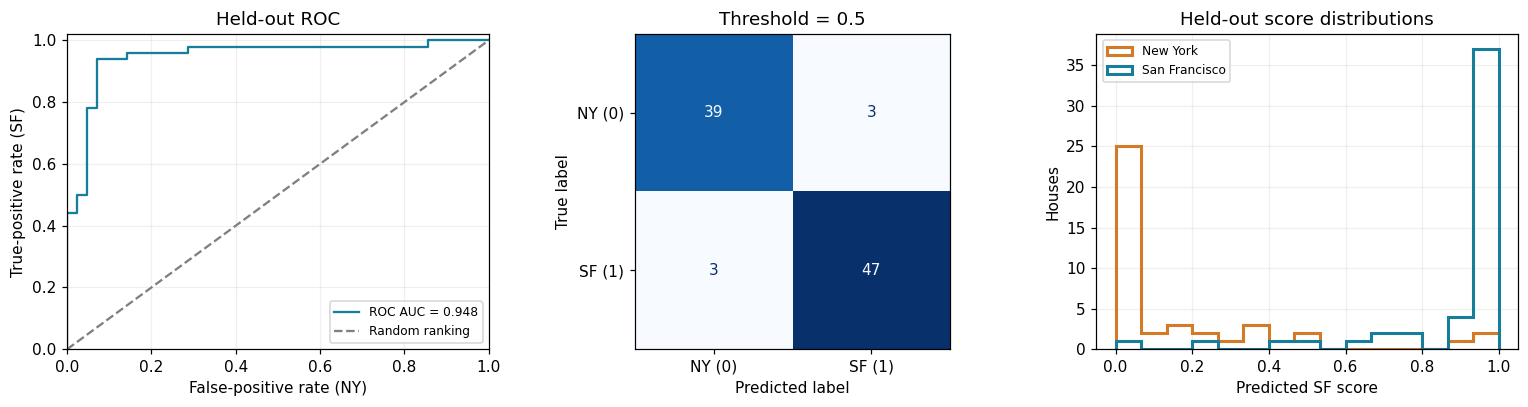

In [77]:
selection = results.groupby(['scheme', 'dropout'], sort=False)['best_val_BCE'].mean()
best_scheme, best_rate = selection.idxmin()
selected_seed = SEEDS[0]
selected_run = runs[(best_scheme, best_rate, selected_seed)]
selected_params = selected_run['best_params']
P_test, cache_test = forward(X_test, selected_params, training=False)
yhat_test = (P_test.ravel() >= 0.5).astype(int)
fpr, tpr, _ = roc_curve(y_test.ravel(), P_test.ravel())
auc_test = roc_auc_score(y_test.ravel(), P_test.ravel())
print(f'Selected: {best_scheme}, dropout={best_rate:g}, seed={selected_seed}, '
      f'checkpoint epoch={selected_run["best_epoch"]}')
print(f'Test BCE: {bce_from_logits(cache_test["Z2"], y_test):.4f}; '
      f'accuracy: {np.mean(yhat_test == y_test.ravel()):.3f}; ROC AUC: {auc_test:.3f}')

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(fpr, tpr, label=f'ROC AUC = {auc_test:.3f}', color='#167d9a')
axes[0].plot([0, 1], [0, 1], '--', color='grey', label='Random ranking')
axes[0].set(xlabel='False-positive rate (NY)', ylabel='True-positive rate (SF)',
            title='Held-out ROC', xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(fontsize=8)
cm = confusion_matrix(y_test.ravel(), yhat_test, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['NY (0)', 'SF (1)']).plot(
    ax=axes[1], colorbar=False, cmap='Blues', values_format='d')
axes[1].grid(False); axes[1].set_title('Threshold = 0.5')
for target, name, color in [(0, 'New York', '#d47a25'), (1, 'San Francisco', '#167d9a')]:
    axes[2].hist(P_test.ravel()[y_test.ravel()==target], bins=np.linspace(0, 1, 16),
                 histtype='step', linewidth=2, label=name, color=color)
axes[2].set(xlabel='Predicted SF score', ylabel='Houses', title='Held-out score distributions')
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()


## For you to investigate!!!

**What you have to do:** in the code below, choose one extension, edit the supplied settings, run it and write a three-sentence conclusion supported by a validation plot. Keep the test set closed. State exactly what you held fixed and what changed.

The supplied extension varies **minibatch size** while retaining no dropout. Try sizes 1, 16, 32, 128, N; a size of 1 reproduces stochastic descent and N reproduces full-batch descent up to row-order floating-point effects. A short run is intended to show optimization dynamics, not determine a universal winner.

Alternative extensions: vary dropout rate over 0, 0.1, 0.25, 0.5 at fixed batch size; or tune learning rate separately for each scheme using validation data and an equal number of candidate runs. For an equal-update-budget study, alter the loop to stop at a prescribed update count and also report examples seen; an epoch may then be incomplete.


In [78]:
RUN_EXTENSION = False  # TODO: switch to True and change at least one setting
EXTENSION_BATCH_SIZES = [1, 16, 32, 128, N]
EXTENSION_EPOCHS = 40
if RUN_EXTENSION:
    fig, ax = plt.subplots(figsize=(7, 4))
    for size in EXTENSION_BATCH_SIZES:
        extra = train(X_train, y_train, X_val, y_val,
                      scheme='minibatch', batch_size=size, dropout_rate=0.0,
                      learning_rate=LEARNING_RATE, epochs=EXTENSION_EPOCHS, seed=SEEDS[0])
        h = extra['history']
        ax.plot(h.epoch, h.val_loss, label=f'batch size={size}')
    ax.set(xlabel='Epoch', ylabel='Validation BCE', title='Student extension: minibatch size')
    ax.legend(); plt.tight_layout(); plt.show()


**Your conclusion:** I changed … while holding … fixed. The validation plot shows … . A limitation of this comparison is … .

<details>
<summary>Example interpretation, not a result to copy</summary>

Smaller batches create more updates per epoch and noisier gradient estimates. A faster decrease per epoch can therefore coexist with a larger wall-time cost. If the full-batch curve is still decreasing, a longer run or learning-rate study is needed before interpreting its higher final loss as poorer achievable performance.

</details>


## Endgame

Before leaving, pick a colleague and explain them:

- Why is the output-logit gradient `(P-y)/m` for sigmoid + BCE?
- Where is dropout's mask reused in the backward pass?
- How many updates does one epoch contain in each scheme?
- Why does dropout not define a fourth update scheme?
- Which split can be used to choose the learning rate, and which is reserved for the final estimate?



### Sources and further reading

- Pietro Vischia, [theory lecture ("CE")](https://www.hep.uniovi.es/vischia/persistent/2026-09to12_ADFM_2_vischia.html).
- R2D3, [housing data and attribution](https://github.com/jadeyee/r2d3-part-1-data), [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). Embedded CSV snapshot retrieved 2026-10-13; its licence applies to the data.
- Srivastava et al. (2014), [Dropout: A Simple Way to Prevent Neural Networks from Overfitting](https://jmlr.org/papers/v15/srivastava14a.html). This notebook uses the equivalent inverted-dropout convention (scale during training).
- scikit-learn, [Common pitfalls: preprocessing and data leakage](https://scikit-learn.org/stable/common_pitfalls.html).
